**Dataset extraction from source link**

In [ ]:
# import requests

# article_id = 29423747
# version = 2

# url = f"https://api.figshare.com/v2/articles/{article_id}/versions/{version}"
# response = requests.get(url, timeout=60)
# response.raise_for_status()

# article = response.json()

# print("Dataset:", article["title"])
# print("\nFiles available:")

# for f in article.get("files", []):
#     print(f'{f["name"]} — {f["size"] / (1024**3):.2f} GB')

In [ ]:
# from pathlib import Path
# import requests
# import os

# download_dir = Path("/content/MMRDR_downloads")
# download_dir.mkdir(parents=True, exist_ok=True)

# session = requests.Session()

# for f in article.get("files", []):
#     name = os.path.basename(f["name"])
#     path = download_dir / name
#     url = f["download_url"]

#     if path.exists() and path.stat().st_size == f["size"]:
#         print(f"Already downloaded: {name}")
#         continue

#     print(f"\nDownloading {name} ({f['size'] / 1e9:.2f} GB)")

#     with session.get(url, stream=True, timeout=(30, 300)) as r:
#         r.raise_for_status()
#         with open(path, "wb") as out:
#             for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
#                 if chunk:
#                     out.write(chunk)

#     print(f"Saved: {path}")

# print("\nDownload step complete.")

In [ ]:
# !apt-get -qq update
# !apt-get -qq install -y p7zip-full

In [ ]:
# import subprocess
# from pathlib import Path

# download_dir = Path("/content/MMRDR_downloads")
# extract_dir = Path("/content/MMRDR_extracted")
# extract_dir.mkdir(parents=True, exist_ok=True)

# first_part = download_dir / "MMRDR.zip.001"

# if not first_part.exists():
#     print("Could not find MMRDR.zip.001. Check the downloaded filenames.")
# else:
#     result = subprocess.run(
#         ["7z", "x", str(first_part), f"-o{extract_dir}", "-y"],
#         text=True
#     )
#     print("Extraction finished with exit code:", result.returncode)

In [ ]:
# from pathlib import Path

# extract_dir = Path("/content/MMRDR_extracted")

# for p in list(extract_dir.rglob("*"))[:30]:
#     print(p)

**Save dataset in Google Drive**

In [ ]:
# from google.colab import drive
# drive.mount("/content/drive")

In [ ]:
# !cp -r /content/MMRDR_extracted /content/drive/MyDrive/

In [ ]:
# from pathlib import Path
# import pandas as pd

# # Find the CFP annotation file
# candidates = list(Path("/content").rglob("FP.csv"))
# print("CSV files found:", candidates)

# assert candidates, (
#     "FP.csv not found. Check where MMRDR-CFP was extracted."
# )

# csv_path = candidates[0]
# cfp_dir = csv_path.parent
# image_dir = cfp_dir / "img"

# df = pd.read_csv(csv_path)

# print("\nCSV path:", csv_path)
# print("Image directory exists:", image_dir.exists())
# print("Dataset shape:", df.shape)
# print("\nColumns:", df.columns.tolist())
# print("\nFirst five rows:")
# display(df.head())

# if "grade" in df.columns:
#     print("\nGrade distribution:")
#     print(df["grade"].value_counts(dropna=False).sort_index())

# print("\nNumber of images in img folder:",
#       len(list(image_dir.glob("*.jpg"))) if image_dir.exists() else 0)

**Import Libraries**

In [1]:
import os
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


**Read dataset and distrubution of Grades**

In [2]:
from pathlib import Path
import pandas as pd

csv_path = Path("/content/drive/MyDrive/MMRDR_extracted/MMRDR-CFP/FP.csv")
cfp_dir = csv_path.parent
df = pd.read_csv(csv_path)

# Extract filename prefixes, e.g. tr or te
df["filename"] = df["image"].apply(lambda x: Path(x).name)
df["prefix"] = df["filename"].str.extract(r"^([a-zA-Z]+)")

print("Filename prefix counts:")
print(df["prefix"].value_counts(dropna=False))

print("\nGrade distribution by prefix:")
print(pd.crosstab(df["prefix"], df["grade"], margins=True))

# Verify image paths
df["path"] = df["image"].apply(lambda x: str(cfp_dir / x))
df["exists"] = df["path"].apply(lambda x: Path(x).is_file())

print("\nMissing images:", (~df["exists"]).sum())
print("All grades:", sorted(df["grade"].dropna().unique()))

Filename prefix counts:
prefix
tr    8893
ts    2225
Name: count, dtype: int64

Grade distribution by prefix:
grade      0     1     2    3    4    All
prefix                                   
tr      5256  1043  1550  503  541   8893
ts      1323   259   409  100  134   2225
All     6579  1302  1959  603  675  11118

Missing images: 0
All grades: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


**Spliting dataset**

In [3]:
ROOT = Path("/content/drive/MyDrive/MMRDR_extracted/MMRDR-CFP")

df = pd.read_csv(ROOT / "FP.csv")
df["filename"] = df["image"].apply(lambda x: Path(x).name)
df["path"] = df["image"].apply(lambda x: str(ROOT / x))
df["prefix"] = df["filename"].str.extract(r"^([a-zA-Z]+)")

# Check that all images exist and grades are valid
assert df["path"].apply(lambda p: Path(p).is_file()).all()
assert set(df["grade"].unique()) == {0, 1, 2, 3, 4}

trainval_df = df[df["prefix"] == "tr"].copy()
test_df = df[df["prefix"] == "ts"].copy()

# Split only the original training partition
train_df, val_df = train_test_split(
    trainval_df,
    test_size=0.20,
    random_state=SEED,
    stratify=trainval_df["grade"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Held-out test:", len(test_df))

print("\nTraining grade counts:")
print(train_df["grade"].value_counts().sort_index())

print("\nValidation grade counts:")
print(val_df["grade"].value_counts().sort_index())

print("\nTest grade counts:")
print(test_df["grade"].value_counts().sort_index())

Training: 7114
Validation: 1779
Held-out test: 2225

Training grade counts:
grade
0    4205
1     834
2    1240
3     402
4     433
Name: count, dtype: int64

Validation grade counts:
grade
0    1051
1     209
2     310
3     101
4     108
Name: count, dtype: int64

Test grade counts:
grade
0    1323
1     259
2     409
3     100
4     134
Name: count, dtype: int64


**Check unreadable images**

In [4]:
##CHECK MULTIPLE IMAGES
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

# Check one image
def check_image(image):
    path = ROOT / image

    try:
        with Image.open(path) as im:
            im.verify()
        return None
    except Exception as e:
        return {
            "image": image,
            "path": str(path),
            "error": str(e)
        }

# Check images in parallel
image_list = df["image"].tolist()

with ThreadPoolExecutor(max_workers=8) as executor:
    results = list(tqdm(
        executor.map(check_image, image_list),
        total=len(image_list),
        desc="Checking images"
    ))

# Keep only unreadable images
bad_images = [r for r in results if r is not None]
bad_df = pd.DataFrame(
    bad_images,
    columns=["image", "path", "error"]
)

print("Total images:", len(image_list))
print("Unreadable images:", len(bad_df))

display(bad_df.head(30))

if not bad_df.empty:
    bad_df.to_csv("/content/cfp_bad_images.csv", index=False)
    print("Saved to /content/cfp_bad_images.csv")

Checking images:   0%|          | 0/11118 [00:00<?, ?it/s]

Total images: 11118
Unreadable images: 1


,image,path,error
0,img/tr000138.jpg,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,cannot identify image file '/content/drive/MyD...


Saved to /content/cfp_bad_images.csv


**Excluding unreadable image**

In [5]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import pandas as pd

df = pd.read_csv(ROOT / "FP.csv")
df["filename"] = df["image"].apply(lambda x: Path(x).name)
df["prefix"] = df["filename"].str.extract(r"^([a-zA-Z]+)")
df["path"] = df["image"].apply(lambda x: str(ROOT / x))

bad_set = set(bad_df["image"]) if len(bad_df) else set()
df = df[~df["image"].isin(bad_set)].copy()

trainval_df = df[df["prefix"] == "tr"].copy()
test_df = df[df["prefix"] == "ts"].copy()

train_df, val_df = train_test_split(
    trainval_df,
    test_size=0.20,
    random_state=42,
    stratify=trainval_df["grade"]
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))
print("Excluded unreadable files:", len(bad_set))

Training: 7113
Validation: 1779
Test: 2225
Excluded unreadable files: 1


**Preprocessing and data augmentation**

In [6]:
IMG_SIZE = 224
BATCH_SIZE = 32

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(
        brightness=0.10,
        contrast=0.10,
        saturation=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )])

**Pytorch dataset**

In [7]:
class CFPDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        try:
            with Image.open(row["path"]) as im:
                image = im.convert("RGB")
                image.load()
        except Exception as e:
            raise RuntimeError(
                f"Cannot read image: {row['path']}. Error: {e}"
            ) from e

        if self.transform:
            image = self.transform(image)

        return image, int(row["grade"])

In [8]:
train_ds = CFPDataset(train_df, train_transform)
val_ds = CFPDataset(val_df, eval_transform)
test_ds = CFPDataset(test_df, eval_transform)

train_loader = DataLoader(
    train_ds, batch_size=32, shuffle=True,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_ds, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_ds, batch_size=32, shuffle=False,
    num_workers=2, pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
print("Label batch:", labels.shape)

print("DataLoaders recreated successfully.")

Image batch: torch.Size([32, 3, 224, 224])
Label batch: torch.Size([32])
DataLoaders recreated successfully.


**EfficientNet_B0 Model**

In [9]:
classes = np.array([0, 1, 2, 3, 4])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=train_df["grade"].to_numpy()
)

class_weights = torch.tensor(
    class_weights, dtype=torch.float32, device=device
)

weights = models.EfficientNet_B0_Weights.DEFAULT
model = models.efficientnet_b0(weights=weights)

num_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(num_features, 5)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(
    model.parameters(), lr=1e-4, weight_decay=1e-4
)

print(model.classifier)
print("Class weights:", class_weights.cpu().numpy())

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 169MB/s]

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=5, bias=True)
)
Class weights: [0.33839202 1.7057554  1.147258   3.538806   3.2854505 ]


**Model training**

In [10]:
EPOCHS = 10            #jsut to check 5
PATIENCE = 3

best_val_f1 = -1.0
epochs_without_improvement = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_f1": [],
    "val_accuracy": []
}

save_path = "/content/best_effnet_cfp.pth"

def run_epoch(loader, training):
    model.train() if training else model.eval()

    total_loss = 0.0
    all_labels = []
    all_preds = []

    for x, y in loader:
        x = x.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        if training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                loss.backward()
                optimizer.step()

        total_loss += loss.item() * x.size(0)
        preds = logits.argmax(dim=1)

        all_labels.extend(y.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(
        all_labels, all_preds,
        labels=[0, 1, 2, 3, 4],
        average="macro",
        zero_division=0
    )

    return avg_loss, accuracy, macro_f1

for epoch in range(EPOCHS):
    train_loss, _, _ = run_epoch(train_loader, training=True)

    val_loss, val_acc, val_f1 = run_epoch(
        val_loader, training=False
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_f1"].append(val_f1)
    history["val_accuracy"].append(val_acc)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train loss: {train_loss:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.4f} | "
        f"Val macro-F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        epochs_without_improvement = 0

        torch.save({
            "model_state_dict": model.state_dict(),
            "best_val_f1": best_val_f1,
            "classes": [0, 1, 2, 3, 4]
        }, save_path)

    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print("Early stopping.")
        break

print("Best validation macro-F1:", best_val_f1)
print("Best model saved at:", save_path)

Epoch 1/5 | Train loss: 1.2154 | Val loss: 0.9605 | Val accuracy: 0.6892 | Val macro-F1: 0.5717
Epoch 2/5 | Train loss: 0.8884 | Val loss: 0.8320 | Val accuracy: 0.6852 | Val macro-F1: 0.6135
Epoch 3/5 | Train loss: 0.7520 | Val loss: 0.8008 | Val accuracy: 0.7611 | Val macro-F1: 0.6614
Epoch 4/5 | Train loss: 0.6692 | Val loss: 0.8529 | Val accuracy: 0.7678 | Val macro-F1: 0.6589
Epoch 5/5 | Train loss: 0.6031 | Val loss: 0.8185 | Val accuracy: 0.7723 | Val macro-F1: 0.6801
Best validation macro-F1: 0.6801244654968963
Best model saved at: /content/best_effnet_cfp.pth


**Model Evaluation**

In [11]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay,
    log_loss,
)

# 1. Generate predictions and probabilities
model.eval()
all_probs, all_preds, all_labels = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        logits = model(images)
        probs = torch.softmax(logits.float(), dim=1)

        all_probs.append(probs.cpu().numpy())
        all_preds.extend(probs.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

y_true = np.asarray(all_labels, dtype=int)
y_pred = np.asarray(all_preds, dtype=int)
probs = np.concatenate(all_probs, axis=0)

classes = [0, 1, 2, 3, 4]
class_names = [
    "Grade 0", "Grade 1", "Grade 2", "Grade 3", "Grade 4"
]

assert len(y_true) == len(test_df), (
    "Prediction count differs from test_df. Check test_loader and test_df alignment."
)
assert set(np.unique(y_true)).issubset(set(classes))

# 2. Overall metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, labels=classes,
                    average="macro", zero_division=0)
weighted_f1 = f1_score(y_true, y_pred, labels=classes,
                       average="weighted", zero_division=0)
balanced_acc = balanced_accuracy_score(y_true, y_pred)
qwk = cohen_kappa_score(y_true, y_pred, labels=classes, weights="quadratic")

print("HELD-OUT TEST METRICS")
print(f"Test images:              {len(y_true)}")
print(f"Accuracy:                 {accuracy:.4f}")
print(f"Macro-F1:                 {macro_f1:.4f}")
print(f"Weighted-F1:              {weighted_f1:.4f}")
print(f"Balanced accuracy:        {balanced_acc:.4f}")
print(f"Quadratic weighted kappa: {qwk:.4f}")

print("\nPER-CLASS PERFORMANCE")
report = classification_report(
    y_true, y_pred,
    labels=classes,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)
report_df = pd.DataFrame(report).T
display(report_df.round(4))

HELD-OUT TEST METRICS
Test images:              2225
Accuracy:                 0.7321
Macro-F1:                 0.6162
Weighted-F1:              0.7424
Balanced accuracy:        0.6459
Quadratic weighted kappa: 0.8485

PER-CLASS PERFORMANCE


,precision,recall,f1-score,support
Grade 0,0.9216,0.8707,0.8955,1323.0000
Grade 1,0.3245,0.4749,0.3856,259.0000
Grade 2,0.6124,0.4597,0.5251,409.0000
Grade 3,0.4320,0.7300,0.5428,100.0000
Grade 4,0.7750,0.6940,0.7323,134.0000
accuracy,0.7321,0.7321,0.7321,0.7321
macro avg,0.6131,0.6459,0.6162,2225.0000
weighted avg,0.7644,0.7321,0.7424,2225.0000


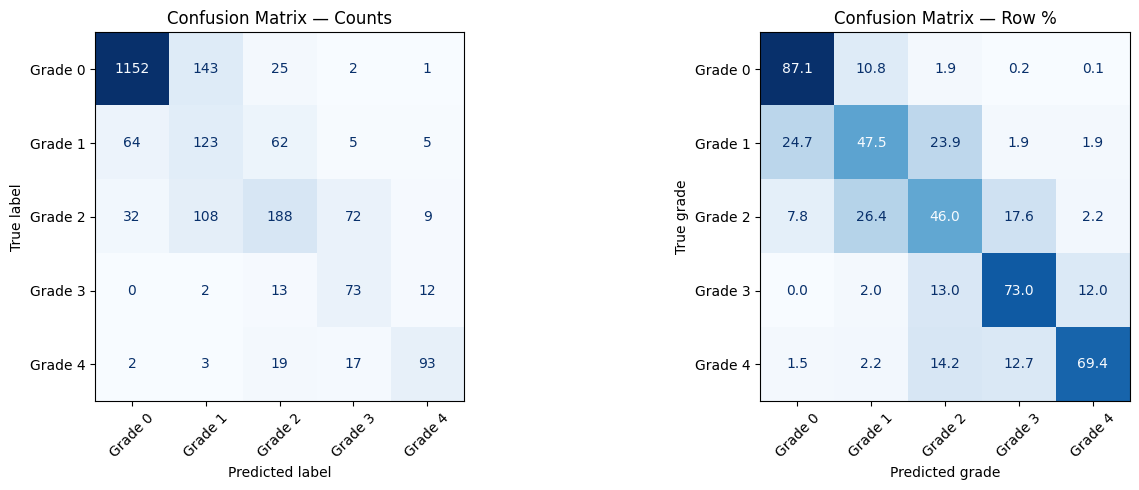

In [12]:
#Confusion matrix: counts and row-normalized percentages
cm = confusion_matrix(y_true, y_pred, labels=classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=class_names
).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Confusion Matrix — Counts")
axes[0].tick_params(axis="x", rotation=45)

row_sums = cm.sum(axis=1, keepdims=True)
cm_pct = np.divide(
    cm, row_sums,
    out=np.zeros_like(cm, dtype=float),
    where=row_sums != 0
) * 100

ConfusionMatrixDisplay(
    confusion_matrix=cm_pct, display_labels=class_names
).plot(ax=axes[1], cmap="Blues", values_format=".1f", colorbar=False)
axes[1].set_title("Confusion Matrix — Row %")
axes[1].set_xlabel("Predicted grade")
axes[1].set_ylabel("True grade")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

**Severity-specific errors**

In [13]:
# Severity-specific errors
grade_diff = y_pred - y_true
wrong = y_pred != y_true
under = y_pred < y_true
over = y_pred > y_true
large_error = np.abs(grade_diff) >= 2

print("\nSEVERITY ERROR ANALYSIS")
print(f"All incorrect predictions:          {wrong.sum()} / {len(y_true)}")
print(f"Underestimated severity:            {under.sum()} / {len(y_true)} "
      f"({under.mean():.2%})")
print(f"Overestimated severity:             {over.sum()} / {len(y_true)} "
      f"({over.mean():.2%})")
print(f"Errors of 2 or more grades:          {large_error.sum()} / {len(y_true)} "
      f"({large_error.mean():.2%})")

# Underestimation rate for each true grade
severity_rows = []
for grade in classes:
    mask = y_true == grade
    severity_rows.append({
        "true_grade": grade,
        "support": int(mask.sum()),
        "underestimated": int(np.sum((y_true == grade) & under)),
        "underestimation_rate": (
            float(np.mean(y_pred[mask] < grade)) if mask.any() else np.nan
        ),
        "exact_accuracy": (
            float(np.mean(y_pred[mask] == grade)) if mask.any() else np.nan
        ),
    })

severity_df = pd.DataFrame(severity_rows)
display(severity_df.round(4))

# Clinically important grade pairs, including distant errors.
print("\nGRADE 0 vs GRADES 3–4")
for actual in [0, 3, 4]:
    for predicted in [0, 3, 4]:
        if actual != predicted:
            n = int(np.sum((y_true == actual) & (y_pred == predicted)))
            print(f"Actual {actual}, predicted {predicted}: {n}")


SEVERITY ERROR ANALYSIS
All incorrect predictions:          596 / 2225
Underestimated severity:            260 / 2225 (11.69%)
Overestimated severity:             336 / 2225 (15.10%)
Errors of 2 or more grades:          105 / 2225 (4.72%)


,true_grade,support,underestimated,underestimation_rate,exact_accuracy
0,0,1323,0,0.0000,0.8707
1,1,259,64,0.2471,0.4749
2,2,409,140,0.3423,0.4597
3,3,100,15,0.1500,0.7300
4,4,134,41,0.3060,0.6940



GRADE 0 vs GRADES 3–4
Actual 0, predicted 3: 2
Actual 0, predicted 4: 1
Actual 3, predicted 0: 0
Actual 3, predicted 4: 12
Actual 4, predicted 0: 2
Actual 4, predicted 3: 17


**Error Table (review images)**

In [14]:
# Create an error table with image paths for manual review.
error_df = test_df.reset_index(drop=True).copy()
error_df["true_grade"] = y_true
error_df["predicted_grade"] = y_pred
error_df["confidence"] = probs.max(axis=1)
error_df["true_grade_probability"] = probs[
    np.arange(len(y_true)), y_true
]
error_df["grade_difference"] = grade_diff
error_df["underestimated"] = under
error_df["large_error"] = large_error

# Highest-priority errors: severity underestimated, then largest grade gap.
priority_errors = error_df[error_df["true_grade"] != error_df["predicted_grade"]].copy()
priority_errors["absolute_gap"] = priority_errors["grade_difference"].abs()
priority_errors = priority_errors.sort_values(
    ["underestimated", "absolute_gap", "confidence"],
    ascending=[False, False, False]
)

print("\nREPRESENTATIVE MISCLASSIFICATIONS — REVIEW THESE IMAGES")
display(priority_errors.head(20))

# Especially important: severe DR incorrectly predicted as mild/no DR,
# or errors spanning at least two grades.
critical_errors = error_df[
    ((error_df["true_grade"] >= 3) & (error_df["predicted_grade"] <= 1))
    | (error_df["large_error"])
].copy()

print("\nHIGH-PRIORITY CLINICAL ERROR CANDIDATES")
display(critical_errors.head(30))


REPRESENTATIVE MISCLASSIFICATIONS — REVIEW THESE IMAGES


,type,image,grade,lesion,lr,filename,prefix,path,true_grade,predicted_grade,confidence,true_grade_probability,grade_difference,underestimated,large_error,absolute_gap
2064,FP,img/ts002065.jpg,4,"[1, 0, 0, 0, 1, 0, 0]",0,ts002065.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,0,0.817781,0.004455,-4,True,True,4
984,FP,img/ts000985.jpg,4,"[1, 1, 0, 0, 0, 1, 0]",0,ts000985.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,0,0.494389,0.003576,-4,True,True,4
2076,FP,img/ts002077.jpg,4,"[1, 0, 0, 0, 1, 0, 0]",0,ts002077.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,1,0.892897,0.000181,-3,True,True,3
1397,FP,img/ts001398.jpg,4,"[0, 0, 0, 0, 1, 0, 0]",1,ts001398.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,1,0.572936,0.030970,-3,True,True,3
2099,FP,img/ts002100.jpg,4,"[1, 0, 0, 0, 1, 0, 0]",1,ts002100.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,1,0.495754,0.113528,-3,True,True,3
1946,FP,img/ts001947.jpg,2,"[1, 1, 1, 0, 0, 0, 0]",1,ts001947.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.966261,0.021628,-2,True,True,2
393,FP,img/ts000394.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",0,ts000394.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.955362,0.022013,-2,True,True,2
1623,FP,img/ts001624.jpg,4,"[1, 0, 1, 0, 1, 0, 0]",1,ts001624.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,2,0.919204,0.004968,-2,True,True,2
1696,FP,img/ts001697.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",0,ts001697.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.904377,0.058058,-2,True,True,2
1600,FP,img/ts001601.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",0,ts001601.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.865301,0.037173,-2,True,True,2



HIGH-PRIORITY CLINICAL ERROR CANDIDATES


,type,image,grade,lesion,lr,filename,prefix,path,true_grade,predicted_grade,confidence,true_grade_probability,grade_difference,underestimated,large_error
49,FP,img/ts000050.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",0,ts000050.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.396514,0.240970,-2,True,True
50,FP,img/ts000051.jpg,0,"[0, 0, 0, 0, 0, 0, 0]",1,ts000051.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,0,2,0.426810,0.376110,2,False,True
78,FP,img/ts000079.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",1,ts000079.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.479022,0.080787,-2,True,True
100,FP,img/ts000101.jpg,1,"[1, 1, 0, 0, 0, 0, 0]",0,ts000101.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,1,4,0.771063,0.040739,3,False,True
128,FP,img/ts000129.jpg,2,"[1, 1, 1, 0, 0, 0, 0]",1,ts000129.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,4,0.675361,0.079440,2,False,True
149,FP,img/ts000150.jpg,0,"[0, 0, 0, 0, 0, 0, 0]",0,ts000150.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,0,2,0.764346,0.011107,2,False,True
155,FP,img/ts000156.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",1,ts000156.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.834494,0.079816,-2,True,True
168,FP,img/ts000169.jpg,2,"[1, 0, 1, 0, 0, 0, 0]",1,ts000169.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,2,0,0.394564,0.214328,-2,True,True
201,FP,img/ts000202.jpg,4,"[1, 0, 1, 0, 1, 0, 0]",0,ts000202.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,4,2,0.398812,0.208409,-2,True,True
236,FP,img/ts000237.jpg,0,"[0, 0, 0, 0, 0, 0, 0]",1,ts000237.jpg,ts,/content/drive/MyDrive/MMRDR_extracted/MMRDR-C...,0,2,0.477649,0.215149,2,False,True


**Reliability**


RELIABILITY METRICS
Expected Calibration Error (ECE, 10 bins): 0.0368


,confidence_bin,count,mean_confidence,accuracy
0,0.0–0.1,0,NaN,NaN
1,0.1–0.2,0,NaN,NaN
2,0.2–0.3,5,0.2809,0.2000
3,0.3–0.4,44,0.3725,0.2500
4,0.4–0.5,203,0.4596,0.4089
5,0.5–0.6,274,0.5485,0.4927
6,0.6–0.7,259,0.6486,0.5637
7,0.7–0.8,313,0.7480,0.7125
8,0.8–0.9,351,0.8536,0.8262
9,0.9–1.0,776,0.9636,0.9536


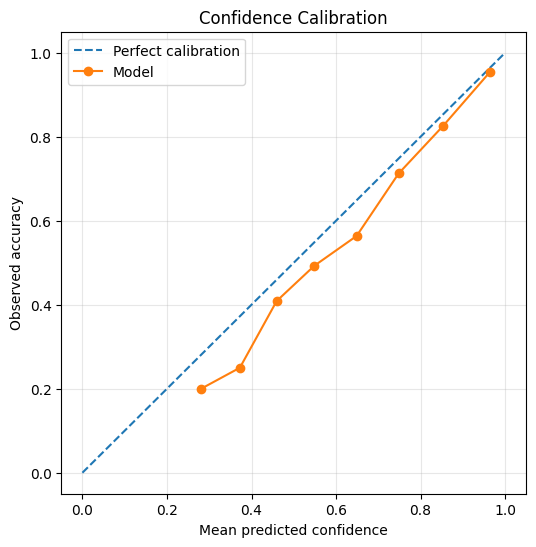

In [15]:
# Expected Calibration Error (ECE), using 10 confidence bins.
confidence = probs.max(axis=1)
correct = (y_pred == y_true).astype(float)

def expected_calibration_error(conf, corr, n_bins=10):
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    bin_rows = []

    for i in range(n_bins):
        # Include confidence=1.0 in the final bin.
        if i == n_bins - 1:
            mask = (conf >= edges[i]) & (conf <= edges[i + 1])
        else:
            mask = (conf >= edges[i]) & (conf < edges[i + 1])

        count = int(mask.sum())
        if count:
            mean_conf = float(conf[mask].mean())
            mean_acc = float(corr[mask].mean())
            ece += (count / len(conf)) * abs(mean_acc - mean_conf)
        else:
            mean_conf, mean_acc = np.nan, np.nan

        bin_rows.append({
            "confidence_bin": f"{edges[i]:.1f}–{edges[i+1]:.1f}",
            "count": count,
            "mean_confidence": mean_conf,
            "accuracy": mean_acc,
        })

    return ece, pd.DataFrame(bin_rows)

ece, calibration_df = expected_calibration_error(confidence, correct)

print("\nRELIABILITY METRICS")
print(f"Expected Calibration Error (ECE, 10 bins): {ece:.4f}")

display(calibration_df.round(4))

# Reliability diagram
valid_bins = calibration_df.dropna(subset=["accuracy"])
plt.figure(figsize=(6, 6))
plt.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
plt.plot(
    valid_bins["mean_confidence"],
    valid_bins["accuracy"],
    marker="o",
    label="Model"
)
plt.xlabel("Mean predicted confidence")
plt.ylabel("Observed accuracy")
plt.title("Confidence Calibration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Explainability of Model using GRAD-CAM, LIME and LLAMA**

In [16]:
!pip -q install lime scikit-image

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [17]:
!pip -q install opencv-python-headless

In [66]:
!apt-get update -qq
!apt-get install -y zstd

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
zstd is already the newest version (1.5.5+dfsg2-2build1.1).
0 upgraded, 0 newly installed, 0 to remove and 5 not upgraded.


In [68]:
!curl -fsSL https://ollama.com/install.sh | sh
!pip install -q ollama

>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [78]:
import subprocess
import time

ollama_server = subprocess.Popen(
    ["ollama", "serve"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL)

time.sleep(5)

In [79]:
!ollama pull llama3.2:3b

In [21]:
from PIL import Image
from lime.lime_image import LimeImageExplainer
from skimage.segmentation import slic, mark_boundaries
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import cv2
from torchvision import transforms
from torchvision.models import efficientnet_b0
from torch import nn
import json
import torch.nn as nn
from torchvision import models, transforms

In [41]:
#The LLM never sees the image. It only receives structured facts produced by
#your classifier and explainers, and is told not to add anything else.

GRADES = ["0 - No DR", "1 - Mild", "2 - Moderate", "3 - Severe", "4 - Proliferative"]


# ---------------------------------------------------------------------------
# 1) Turn your model outputs into plain facts
# ---------------------------------------------------------------------------
def describe_gradcam(cam, retina_mask=None):
    """cam: 2D array in [0,1] (Grad-CAM). Returns a coarse text description of where it peaks.
    retina_mask: optional boolean 2D array, True inside the retina (ignores black background)."""
    cam = np.asarray(cam, dtype=float)
    if retina_mask is not None:
        cam = np.where(retina_mask, cam, 0.0)
    h, w = cam.shape
    y, x = np.unravel_index(np.argmax(cam), cam.shape)
    vert = "upper" if y < h / 3 else "lower" if y > 2 * h / 3 else "middle"
    horiz = "left" if x < w / 3 else "right" if x > 2 * w / 3 else "central"
    share = float((cam > 0.5).mean())  # fraction of image with strong attention
    return (f"Grad-CAM peak attention in the {vert}-{horiz} part of the image; "
            f"{share:.0%} of the image has strong attention.")


def describe_lime(weights, top_k=5):
    """weights: dict {superpixel_id: weight} from LIME for the predicted class."""
    items = sorted(weights.items(), key=lambda kv: abs(kv[1]), reverse=True)[:top_k]
    pos = [(i, w) for i, w in items if w > 0]
    neg = [(i, w) for i, w in items if w < 0]
    return (f"LIME top {top_k} patches: {len(pos)} support the predicted class, "
            f"{len(neg)} oppose it. Largest absolute weight: {abs(items[0][1]):.3f}.")


def build_facts(probs, cam, lime_weights, lesions=None, retina_mask=None):
    probs = np.asarray(probs, dtype=float)
    pred = int(np.argmax(probs))
    facts = {
        "predicted_grade": GRADES[pred],
        "confidence": round(float(probs[pred]), 3),
        "class_probabilities": {GRADES[i]: round(float(p), 3) for i, p in enumerate(probs)},
        "gradcam": describe_gradcam(cam, retina_mask),
        "lime": describe_lime(lime_weights),
        "lesions_detected": lesions if lesions is not None else "not available",
    }
    return facts


# ---------------------------------------------------------------------------
# 2) Ask a local Llama to narrate ONLY those facts
# ---------------------------------------------------------------------------
SYSTEM = (
    "You are assisting an ophthalmologist who is reviewing an AI diabetic "
    "retinopathy grading result. Use ONLY the facts provided. Do not invent "
    "findings, lesions or measurements. If something is not in the facts, say it "
    "is not available. This is decision support, not a diagnosis."
)

USER_TEMPLATE = """Facts from the classifier and explainers (JSON):
{facts}

Write:
1. Prediction: one sentence with grade and confidence.
2. Why: two sentences explaining what the explanations show.
3. Reliability: one sentence on how much to trust this (use the confidence and any disagreement).
4. Check: one sentence on what the clinician should verify.
"""


def explain_with_llama(facts, model="llama3.2:3b"):
    import ollama  # imported here so the rest of the file works without it
    resp = ollama.chat(
        model=model,
        messages=[
            {"role": "system", "content": SYSTEM},
            {"role": "user", "content": USER_TEMPLATE.format(facts=json.dumps(facts, indent=2))},
        ],
        options={"temperature": 0.1},  # low = stable, less creative
    )
    return resp["message"]["content"]


# ---------------------------------------------------------------------------
# 3) Simple hallucination guard: flag lesion words the facts never mentioned
# ---------------------------------------------------------------------------
LESION_WORDS = ["haemorrhage", "hemorrhage", "exudate", "microaneurysm",
                "neovascularisation", "neovascularization", "cotton-wool", "oedema", "edema"]


def unsupported_terms(text, facts):
    allowed = json.dumps(facts).lower()
    return [w for w in LESION_WORDS if w in text.lower() and w not in allowed]

In [25]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load the checkpoint
checkpoint = torch.load(
    "/content/best_effnet_cfp.pth",
    map_location=device,
    weights_only=True
)

# Recreate the same model architecture used during training
model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features, 5
)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device).eval()

print("Model loaded. Best validation macro-F1:",
      checkpoint.get("best_val_f1"))

Model loaded. Best validation macro-F1: 0.6801244654968963


In [59]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Change this to the path of a real retinal image in Colab
image_path = "/content/drive/MyDrive/MMRDR_extracted/MMRDR-CFP/img/ts000001.jpg"

image = Image.open(image_path).convert("RGB")
image_np = np.array(image)

input_tensor = transform(image).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(input_tensor)
    probs = torch.softmax(logits, dim=1)[0].cpu().numpy()

predicted_grade = int(np.argmax(probs))

print("Predicted grade:", GRADES[predicted_grade])
print("Class probabilities:", np.round(probs, 3))

Predicted grade: 0 - No DR
Class probabilities: [0.945 0.053 0.002 0.    0.   ]


In [60]:
import torch.nn.functional as F

# EfficientNet-B0's final feature layer
target_layer = model.features[-1]

saved_features = []
saved_gradients = []

def forward_hook(module, inputs, output):
    saved_features.append(output)
    output.register_hook(
        lambda grad: saved_gradients.append(grad)
    )

hook = target_layer.register_forward_hook(forward_hook)

model.zero_grad()
logits = model(input_tensor)
logits[0, predicted_grade].backward()

features = saved_features[0]
gradients = saved_gradients[0]

weights = gradients.mean(dim=(2, 3), keepdim=True)
cam_tensor = torch.relu((weights * features).sum(dim=1, keepdim=True))

cam_tensor = F.interpolate(
    cam_tensor,
    size=(image_np.shape[0], image_np.shape[1]),
    mode="bilinear",
    align_corners=False
)

cam = cam_tensor[0, 0].detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

hook.remove()
model.zero_grad()

print("Grad-CAM shape:", cam.shape)

Grad-CAM shape: (1467, 1473)


In [61]:
from lime import lime_image

def predict_images(images):
    """Return probabilities for a batch of RGB images."""
    batch = torch.stack([
        transform(Image.fromarray(np.asarray(img).astype(np.uint8)))
        for img in images
    ]).to(device)

    model.eval()
    with torch.no_grad():
        logits = model(batch)
        probabilities = torch.softmax(logits, dim=1)

    return probabilities.cpu().numpy()


explainer = lime_image.LimeImageExplainer(random_state=42)

lime_exp = explainer.explain_instance(
    image=image_np,
    classifier_fn=predict_images,
    labels=[predicted_grade],
    num_samples=500,
    num_features=10,
    hide_color=0
)

# Real LIME weights for the predicted grade
lime_weights = dict(lime_exp.local_exp[predicted_grade])

print("LIME weights:", lime_weights)

  0%|          | 0/500 [00:00<?, ?it/s]

LIME weights: {np.int64(1303): np.float64(0.01055161419290077), np.int64(812): np.float64(0.010498053610187926), np.int64(1648): np.float64(0.010421250979576193), np.int64(1051): np.float64(0.010400400271465023), np.int64(478): np.float64(0.009297371452306974), np.int64(511): np.float64(0.008308108012932192), np.int64(385): np.float64(0.00789967221783756), np.int64(650): np.float64(0.005843879028025678), np.int64(1727): np.float64(0.005840097419719906), np.int64(1120): np.float64(0.005693286586120709)}


In [80]:
# Build facts from the real model and explainers
facts = build_facts(
    probs=probs,
    cam=cam,
    lime_weights=lime_weights,
    lesions= None  # No separate lesion detector is being used
)

print(json.dumps(facts, indent=2))

# Ask the local Llama model to narrate these facts
text = explain_with_llama(facts, model="llama3.2:3b")

print("\n--- LLM explanation ---\n")
print(text)

# Basic check for unsupported lesion claims
bad = unsupported_terms(text, facts)

if bad:
    print("\nWARNING: Check these potentially unsupported terms:", bad)

{
  "predicted_grade": "0 - No DR",
  "confidence": 0.945,
  "class_probabilities": {
    "0 - No DR": 0.945,
    "1 - Mild": 0.053,
    "2 - Moderate": 0.002,
    "3 - Severe": 0.0,
    "4 - Proliferative": 0.0
  },
  "gradcam": "Grad-CAM peak attention in the middle-central part of the image; 14% of the image has strong attention.",
  "lime": "LIME top 5 patches: 5 support the predicted class, 0 oppose it. Largest absolute weight: 0.011.",
  "lesions_detected": "not available"
}

--- LLM explanation ---

Here are the requested explanations:

1. Prediction: The predicted grade is 0 - No DR with a confidence of 94.5%, indicating a high level of certainty in the classification.

2. Why: The Grad-CAM explanation highlights the middle-central part of the image as the most attended region, suggesting that the model is focusing on this area when making the prediction. The LIME explanation shows that the top 5 patches support the predicted class, with the largest absolute weight being 0.011,

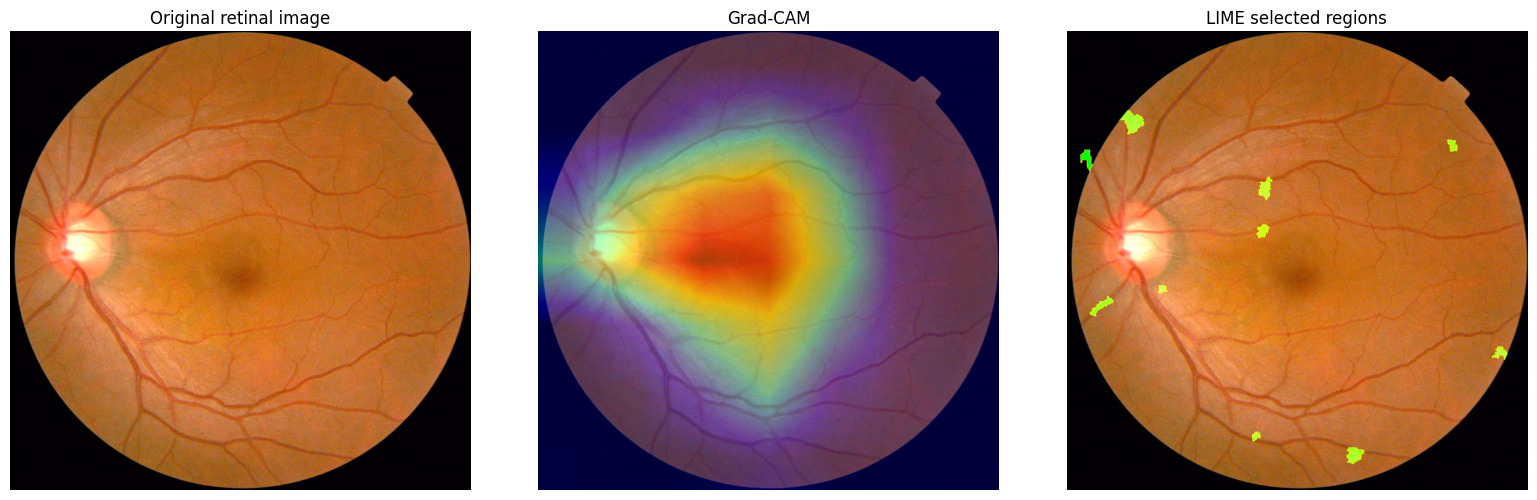

In [81]:
import matplotlib.pyplot as plt
from skimage.segmentation import mark_boundaries

# LIME visualization: show selected superpixel boundaries
lime_image_out, lime_mask = lime_exp.get_image_and_mask(
    label=predicted_grade,
    positive_only=False,
    num_features=10,
    hide_rest=False
)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].imshow(image_np)
axes[0].set_title("Original retinal image")

axes[1].imshow(image_np)
axes[1].imshow(cam, cmap="jet", alpha=0.45)
axes[1].set_title("Grad-CAM")

axes[2].imshow(mark_boundaries(lime_image_out, lime_mask))
axes[2].set_title("LIME selected regions")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()